# Comparing LLM Classification Approaches: Zero-Shot vs Few-Shot vs QLoRA Fine-Tune

**Task:** classify Amazon Reviews '23 **Gift Cards** reviews as `POSITIVE`, `NEUTRAL`, or `NEGATIVE`
(`4-5` stars = POSITIVE, `3` = NEUTRAL, `1-2` = NEGATIVE).

**Three approaches, same 300 test reviews:**

1. **Zero-shot** prompting of a hosted model (`cyankiwi/Qwen3.6-35B-A3B-AWQ-4bit` via the class endpoint at `http://dobolyi.com:9001/v1`),
2. **Few-shot** prompting of the same model (6 examples, 2 per class, all drawn from the prescribed training set),
3. **Fine-tuned** small open-weight model (`Qwen2.5-3B-Instruct`, 4-bit QLoRA, trained with **Unsloth** on the prescribed 900 training reviews).

**Safeguards enforced in this notebook:** prediction inputs are review title + text only (never the rating or the reference label);
no test reviews are used for training or few-shot examples; invalid model outputs are recorded, never guessed;
all fixed-split assertions run before training and before every scoring step and stop execution on failure.
The API key is read from a Colab secret and is never printed.


## 1. Environment

Installs Unsloth, its dependencies, and verifies the GPU/runtime. The actual GPU used for this run is reported
in the fine-tuning section (T4 compatibility is tested directly, on-device).

In [5]:
import sys, subprocess, time, os

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

pip_install("unsloth")
pip_install("statsmodels")  # exact McNemar tests
try:
    import unsloth
    print("unsloth", getattr(unsloth, "__version__", "?"))
except Exception as e:
    print("PyPI unsloth import failed (%s); installing from git..." % e)
    pip_install("unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git")
    import unsloth

import torch, transformers, datasets, requests
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
unsloth 2026.11.1
torch 2.11.0+cu130 | transformers 5.17.0 | datasets 4.8.5
CUDA available: True
GPU: Tesla T4


## 2. Fixed dataset and prescribed splits (do not change)

Source: `https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Gift_Cards.jsonl.gz`

Rules implemented exactly as prescribed:

* Preserve file order; `original_row` = original 1-based line number.
* Skip blank lines and reviews with fewer than 3 characters of text after trimming; missing text is treated as empty.
* The remaining reviews are numbered `filtered_index`, starting at 0.
* **Training:** `filtered_index` 1,000–19,999 → `random.Random(43).sample(300, per class)` in order POSITIVE, NEUTRAL, NEGATIVE, then one `shuffle` of the combined 900 with that same generator.
* **Validation:** indices 20,000–29,999, first 100 per class (reserved; not used in this assignment).
* **Test:** indices 30,000–39,999, first 100 per class (300 total) — the same 300 reviews for all three approaches.

In [6]:
import gzip, json, urllib.request, random

DATA_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Gift_Cards.jsonl.gz"
DATA_PATH = "Gift_Cards.jsonl.gz"
if not os.path.exists(DATA_PATH):
    print("Downloading dataset ...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
print("file size MB:", round(os.path.getsize(DATA_PATH) / 1e6, 2))

def classify(rating):
    if rating is None:
        return None
    r = float(rating)
    if r >= 4.0: return "POSITIVE"
    if r == 3.0: return "NEUTRAL"
    if r <= 2.0: return "NEGATIVE"
    return None

records = []
original_row = 0
skipped_blank, skipped_short = 0, 0
with gzip.open(DATA_PATH, "rt", encoding="utf-8", errors="replace") as f:
    for line in f:
        original_row += 1
        s = line.strip()
        if not s:
            skipped_blank += 1
            continue
        try:
            d = json.loads(s)
        except ValueError:
            skipped_blank += 1  # unparseable line: skipped like a blank
            continue
        t = d.get("text") or ""
        if not isinstance(t, str):
            t = str(t)
        t = t.strip()
        if len(t) < 3:
            skipped_short += 1
            continue
        records.append({
            "original_row": original_row,
            "filtered_index": len(records),
            "rating": d.get("rating"),
            "title": (d.get("title") or "").strip(),
            "text": t,
            "label": classify(d.get("rating")),
        })

print("raw lines read      :", original_row)
print("valid reviews       :", len(records))
print("skipped blank/malformed:", skipped_blank, "| skipped <3 chars text:", skipped_short)


file size MB: 12.29
raw lines read      : 152410
valid reviews       : 151240
skipped blank/malformed: 0 | skipped <3 chars text: 1170


In [7]:
CLASSES = ["POSITIVE", "NEUTRAL", "NEGATIVE"]

def pool_ids(lo, hi, cls):
    return [r["filtered_index"] for r in records if lo <= r["filtered_index"] <= hi and r["label"] == cls]

# --- Training: random.Random(43), sample per class in order, then shuffle ---
rng = random.Random(43)
train_ids = []
for c in CLASSES:
    train_ids.extend(rng.sample(pool_ids(1000, 19999, c), 300))
rng.shuffle(train_ids)

# --- Validation (reserved, unused in this assignment): first 100 per class ---
val_ids = []
for c in CLASSES:
    val_ids.extend(pool_ids(20000, 29999, c)[:100])

# --- Test: first 100 per class ---
test_ids = []
for c in CLASSES:
    test_ids.extend(pool_ids(30000, 39999, c)[:100])

by_id = {r["filtered_index"]: r for r in records}
train_records = [by_id[i] for i in train_ids]
val_records   = [by_id[i] for i in val_ids]
test_records  = [by_id[i] for i in test_ids]

# ----- 3. REQUIRED DATA CHECKS (failures stop everything downstream) -----
def check(cond, msg):
    if not cond:
        raise AssertionError("FAILED CHECK: " + msg)
    print("PASS:", msg)

check(len(train_ids) == 900 and len(val_ids) == 300 and len(test_ids) == 300, "set sizes are 900 / 300 / 300")
check(len(set(train_ids)) == 900 and len(set(val_ids)) == 300 and len(set(test_ids)) == 300, "IDs unique within each set")
check(len(set(train_ids) & set(val_ids)) == 0 and len(set(train_ids) & set(test_ids)) == 0       and len(set(val_ids) & set(test_ids)) == 0, "no shared IDs across sets")
for c in CLASSES:
    check(sum(1 for r in train_records if r["label"] == c) == 300, "train has exactly 300 " + c)
    check(sum(1 for r in val_records if r["label"] == c) == 100,   "val has exactly 100 " + c)
    check(sum(1 for r in test_records if r["label"] == c) == 100,  "test has exactly 100 " + c)
check(all(1000 <= i <= 19999 for i in train_ids), "train indices within 1,000-19,999")
check(all(20000 <= i <= 29999 for i in val_ids),  "val indices within 20,000-29,999")
check(all(30000 <= i <= 39999 for i in test_ids), "test indices within 30,000-39,999")

from collections import Counter
print("train class distribution:", dict(Counter(r["label"] for r in train_records)))
print("val   class distribution:", dict(Counter(r["label"] for r in val_records)))
print("test  class distribution:", dict(Counter(r["label"] for r in test_records)))
print("first train records:", [(r["filtered_index"], r["label"]) for r in train_records[:3]])


PASS: set sizes are 900 / 300 / 300
PASS: IDs unique within each set
PASS: no shared IDs across sets
PASS: train has exactly 300 POSITIVE
PASS: val has exactly 100 POSITIVE
PASS: test has exactly 100 POSITIVE
PASS: train has exactly 300 NEUTRAL
PASS: val has exactly 100 NEUTRAL
PASS: test has exactly 100 NEUTRAL
PASS: train has exactly 300 NEGATIVE
PASS: val has exactly 100 NEGATIVE
PASS: test has exactly 100 NEGATIVE
PASS: train indices within 1,000-19,999
PASS: val indices within 20,000-29,999
PASS: test indices within 30,000-39,999
train class distribution: {'NEUTRAL': 300, 'POSITIVE': 300, 'NEGATIVE': 300}
val   class distribution: {'POSITIVE': 100, 'NEUTRAL': 100, 'NEGATIVE': 100}
test  class distribution: {'POSITIVE': 100, 'NEUTRAL': 100, 'NEGATIVE': 100}
first train records: [(2114, 'NEUTRAL'), (5555, 'POSITIVE'), (6660, 'NEGATIVE')]


## 3. Prompt templates, few-shot selection, and output contract

* **Inputs:** review title + text only — the target review's rating and reference label never appear in any prompt.
* **Output contract:** the model must reply with exactly one word, `POSITIVE` / `NEUTRAL` / `NEGATIVE`.
  Any other output is recorded as **invalid** (raw text kept in the results) — never replaced by a guessed label.
* **Few-shot:** 6 examples (2 per class), each drawn from the prescribed 900 training reviews:
  the two lowest `filtered_index` reviews of each class within the training set (deterministic, auditable).

In [8]:
SYSTEM_PROMPT = "Classify the sentiment of the Amazon review below. Reply with exactly one word: POSITIVE, NEUTRAL, or NEGATIVE."

def review_text(r):
    title = (r.get("title") or "").strip()
    body = (r.get("text") or "").strip()
    return ("Title: " + title + "\nText: " + body) if title else ("Text: " + body)

def user_prompt(r):
    return "Review:\n" + review_text(r) + "\n\nSentiment:"

def zero_shot_messages(r):
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt(r)}]

def few_shot_messages(examples, r):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex in examples:
        msgs.append({"role": "user", "content": user_prompt(ex)})
        msgs.append({"role": "assistant", "content": ex["label"]})
    msgs.append({"role": "user", "content": user_prompt(r)})
    return msgs

# --- few-shot selection: 2 per class, lowest filtered_index in the TRAINING set ---
train_sorted = sorted(train_records, key=lambda r: r["filtered_index"])
few_shot_examples = []
for c in CLASSES:
    few_shot_examples.extend([r for r in train_sorted if r["label"] == c][:2])

train_id_set = set(train_ids)
check(len(few_shot_examples) == 6, "6 few-shot examples (2 per class)")
check(all(r["filtered_index"] in train_id_set for r in few_shot_examples), "every few-shot example is one of the 900 training reviews")
print("few-shot picks:", [(r["filtered_index"], r["label"]) for r in few_shot_examples])

LABELS = set(CLASSES)
def parse_label(raw):
    s = (raw or "").strip().upper().strip("\"'\".',;!?: ")
    return s if s in LABELS else None


PASS: 6 few-shot examples (2 per class)
PASS: every few-shot example is one of the 900 training reviews
few-shot picks: [(1091, 'POSITIVE'), (1214, 'POSITIVE'), (1030, 'NEUTRAL'), (1049, 'NEUTRAL'), (1010, 'NEGATIVE'), (1201, 'NEGATIVE')]


In [9]:
# Hosted-model client (class endpoint, OpenAI-compatible). Thinking mode is disabled.
API_BASE = "http://dobolyi.com:9001/v1"
API_MODEL = "cyankiwi/Qwen3.6-35B-A3B-AWQ-4bit"

try:
    from google.colab import userdata
    API_KEY = userdata.get("CLASS_API_KEY")
    KEY_SOURCE = "Colab secret 'CLASS_API_KEY'"
except Exception:
    import getpass
    API_KEY = getpass.getpass("CLASS_API_KEY (no Colab secret found): ")
    KEY_SOURCE = "manual entry"

assert API_KEY, "API key missing — add the Colab secret CLASS_API_KEY (key icon in the left panel) and re-run"
print("API key loaded from:", KEY_SOURCE, "(key itself is never printed)")

def call_model(messages, max_tokens=16, timeout=90, retries=3):
    last = None
    for attempt in range(retries):
        try:
            t0 = time.time()
            resp = requests.post(
                API_BASE + "/chat/completions",
                headers={"Authorization": "Bearer " + API_KEY},
                json={
                    "model": API_MODEL,
                    "messages": messages,
                    "max_tokens": max_tokens,
                    "temperature": 0.0,
                    "chat_template_kwargs": {"enable_thinking": False},
                },
                timeout=timeout,
            )
            resp.raise_for_status()
            data = resp.json()
            raw = (data["choices"][0]["message"].get("content") or "").strip()
            return raw, round(time.time() - t0, 2), (data.get("usage") or {})
        except Exception as e:
            last = e
            time.sleep(2 * (attempt + 1))
    raise RuntimeError("API call failed after %d attempts: %r" % (retries, last))


API key loaded from: Colab secret 'CLASS_API_KEY' (key itself is never printed)


## 4. Approach 1 — zero-shot prompting (hosted model)

In [10]:
def score_test(messages_fn, name, max_tokens=16):
    results = []
    for i, r in enumerate(test_records):
        raw, dt, usage = call_model(messages_fn(r), max_tokens=max_tokens)
        pred = parse_label(raw)
        results.append({
            "filtered_index": r["filtered_index"],
            "original_row": r["original_row"],
            "reference_label": r["label"],
            "raw_output": raw,
            "prediction": pred,
            "valid": pred is not None,
            "latency_s": dt,
        })
        if (i + 1) % 50 == 0:
            print(name, ":", i + 1, "/", len(test_records), "done")
    return results

def assert_aligned(results, name):
    n = len(results)
    ids = [r["filtered_index"] for r in results]
    check(n == 300, name + ": exactly one prediction row per test review (" + str(n) + " rows for 300 reviews)")
    check(len(set(ids)) == 300, name + ": prediction rows have unique test IDs")
    check(set(ids) == set(test_ids), name + ": predictions cover exactly the prescribed 300 test IDs")

zero_shot_results = score_test(zero_shot_messages, "zero-shot")
assert_aligned(zero_shot_results, "zero-shot")


zero-shot : 50 / 300 done
zero-shot : 100 / 300 done
zero-shot : 150 / 300 done
zero-shot : 200 / 300 done
zero-shot : 250 / 300 done
zero-shot : 300 / 300 done
PASS: zero-shot: exactly one prediction row per test review (300 rows for 300 reviews)
PASS: zero-shot: prediction rows have unique test IDs
PASS: zero-shot: predictions cover exactly the prescribed 300 test IDs


In [11]:
def metrics_table(results, name):
    y_true = [r["reference_label"] for r in results]
    y_pred = [r["prediction"] for r in results]
    n = len(results)
    valid = sum(1 for r in results if r["valid"])
    conf = {t: {p: 0 for p in CLASSES} for t in CLASSES}
    for yt, yp in zip(y_true, y_pred):
        if yp is not None:
            conf[yt][yp] += 1
    acc = sum(1 for yt, yp in zip(y_true, y_pred) if yp == yt) / n
    print("---", name, "---")
    print("accuracy       : %.4f" % acc)
    f1s = []
    print("class     tp  precision  recall      f1")
    for c in CLASSES:
        tp = conf[c][c]
        fp = sum(conf[t][c] for t in CLASSES if t != c)
        fn = sum(conf[c][p] for p in CLASSES if p != c)
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec  = tp / (tp + fn) if (tp + fn) else 0.0
        f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        f1s.append(f1)
        print("%-9s%4d%11.4f%9.4f%8.4f" % (c, tp, prec, rec, f1))
    macro_f1 = sum(f1s) / len(f1s)
    print("macro-F1      : %.4f" % macro_f1)
    print("valid/invalid : %d / %d" % (valid, n - valid))
    return {"name": name, "accuracy": acc, "macro_f1": macro_f1, "valid": valid, "invalid": n - valid}

zero_shot_metrics = metrics_table(zero_shot_results, "zero-shot")


--- zero-shot ---
accuracy       : 0.7400
class     tp  precision  recall      f1
POSITIVE   94     0.8319   0.9400  0.8826
NEUTRAL    31     0.8158   0.3100  0.4493
NEGATIVE   97     0.6510   0.9700  0.7791
macro-F1      : 0.7037
valid/invalid : 300 / 0


## 5. Approach 2 — few-shot prompting (6 examples: 2 per class, from the training set)

In [12]:
few_shot_results = score_test(lambda r: few_shot_messages(few_shot_examples, r), "few-shot")
assert_aligned(few_shot_results, "few-shot")
few_shot_metrics = metrics_table(few_shot_results, "few-shot")


few-shot : 50 / 300 done
few-shot : 100 / 300 done
few-shot : 150 / 300 done
few-shot : 200 / 300 done
few-shot : 250 / 300 done
few-shot : 300 / 300 done
PASS: few-shot: exactly one prediction row per test review (300 rows for 300 reviews)
PASS: few-shot: prediction rows have unique test IDs
PASS: few-shot: predictions cover exactly the prescribed 300 test IDs
--- few-shot ---
accuracy       : 0.7500
class     tp  precision  recall      f1
POSITIVE   91     0.8426   0.9100  0.8750
NEUTRAL    38     0.7755   0.3800  0.5101
NEGATIVE   96     0.6713   0.9600  0.7901
macro-F1      : 0.7251
valid/invalid : 300 / 0


## 6. Approach 3 — QLoRA fine-tune with Unsloth

* **Base model:** `unsloth/Qwen2.5-3B-Instruct-unsloth-bnb-4bit` (dynamic 4-bit quantization).
* **Data:** the prescribed 900 training reviews (300 per class); validation set stays untouched.
* **Hyperparameters:** 2 epochs, lr 2e-4, LoRA r=16 / alpha=16, dropout 0, seq len 512,
  batch size 4 with gradient accumulation 2 (effective 8), cosine schedule, warmup 5%, seed 43, adamw_8bit.
* **GPU:** this notebook runs on the T4 runtime (16 GB) — T4 compatibility is tested directly on-device;
  the actual GPU name/VRAM is reported below. Training + inference both fit comfortably (4-bit 3B model ≈ 2–3 GB weights + LoRA optimizer states).

In [13]:
print("Actual GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("VRAM GB:", round(props.total_memory / 1e9, 2))
    if "T4" in torch.cuda.get_device_name(0):
        print("T4 compatibility: tested directly on this T4 device.")
    else:
        print("NOTE: runtime GPU is %s — not a T4; the config below is sized for 16 GB T4." % torch.cuda.get_device_name(0))

from unsloth import FastLanguageModel
base_model_id = "unsloth/Qwen2.5-3B-Instruct-unsloth-bnb-4bit"
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=base_model_id,
    max_seq_length=512,
    dtype=None,
    load_in_4bit=True,
)
print("base model loaded:", base_model_id)


Actual GPU: Tesla T4
VRAM GB: 15.64
T4 compatibility: tested directly on this T4 device.
==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

base model loaded: unsloth/Qwen2.5-3B-Instruct-unsloth-bnb-4bit


In [14]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=43,
    max_seq_length=512,
)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print("trainable params: %s (%0.3f%% of %s)" % (format(trainable, ","), 100.0 * trainable / total, format(total, ",")))


Unsloth 2026.11.1 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 29,933,568 (1.636% of 1,830,055,936)


In [15]:
def make_train_text(r):
    conv = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt(r)},
        {"role": "assistant", "content": r["label"]},
    ]
    return tokenizer.apply_chat_template(conv, tokenize=False, add_generation_prompt=False)

train_texts = [make_train_text(r) for r in train_records]
check(len(train_texts) == 900, "actual prepared training records total exactly 900")
for c in CLASSES:
    check(sum(1 for r, t in zip(train_records, train_texts) if r["label"] == c) == 300,
          "actual prepared training records: exactly 300 " + c)
print("example training text (first 400 chars):")
print(train_texts[0][:400])

from datasets import Dataset
train_ds = Dataset.from_list([{"text": t} for t in train_texts])
print("train dataset rows:", len(train_ds))


PASS: actual prepared training records total exactly 900
PASS: actual prepared training records: exactly 300 POSITIVE
PASS: actual prepared training records: exactly 300 NEUTRAL
PASS: actual prepared training records: exactly 300 NEGATIVE
example training text (first 400 chars):
<|im_start|>system
Classify the sentiment of the Amazon review below. Reply with exactly one word: POSITIVE, NEUTRAL, or NEGATIVE.<|im_end|>
<|im_start|>user
Review:
Title: Three Stars
Text: It works like every other system that wants your money.

Sentiment:<|im_end|>
<|im_start|>assistant
NEUTRAL<|im_end|>

train dataset rows: 900


In [18]:
from trl import SFTTrainer
from transformers import TrainingArguments

training_args = TrainingArguments(
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=11,          # ← replaces warmup_ratio=0.05 (removed in transformers 5.x); ≈5% of 226 steps
    logging_steps=10,
    save_strategy="no",
    output_dir="ft_out",
    seed=43,
    fp16=True,
    optim="adamw_8bit",       # verified still accepted in 5.17
    report_to="none",
)
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_ds,
    dataset_text_field="text",
    max_seq_length=512,
    args=training_args,
)
t0 = time.time()
trainer.train()
train_wall_s = round(time.time() - t0, 1)
print("training wall time (s):", train_wall_s)

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/900 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 900 | Num Epochs = 2 | Total steps = 226
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.


Step,Training Loss
10,4.123127
20,1.595965
30,1.240174
40,1.287578
50,1.263306
60,1.313771
70,1.283446
80,1.169018
90,1.268716
100,1.244598


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!
training wall time (s): 333.7


In [19]:
# Save the LoRA adapter, then bundle exactly the two required files into the submission zip.
import zipfile  # ← needed by this cell

model.save_pretrained("adapter_ft")
tokenizer.save_pretrained("adapter_ft")

if os.path.exists("adapter_ft.zip"):
    os.remove("adapter_ft.zip")
with zipfile.ZipFile("adapter_ft.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("adapter_ft/adapter_model.safetensors", "adapter_model.safetensors")
    z.write("adapter_ft/adapter_config.json", "adapter_config.json")

import shutil, hashlib
names = sorted(zipfile.ZipFile("adapter_ft.zip").namelist())
check(names == ["adapter_config.json", "adapter_model.safetensors"],
      "adapter zip contains exactly adapter_model.safetensors + adapter_config.json")
print("adapter zip size MB:", round(os.path.getsize("adapter_ft.zip") / 1e6, 2))
cfg = json.load(open("adapter_ft/adapter_config.json"))
print("adapter r / lora_alpha:", cfg.get("r"), cfg.get("lora_alpha"), "| base:", cfg.get("base_model_name_or_path"))

Unsloth: Restored added_tokens_decoder metadata in adapter_ft/tokenizer_config.json.


PASS: adapter zip contains exactly adapter_model.safetensors + adapter_config.json
adapter zip size MB: 110.86
adapter r / lora_alpha: 16 16 | base: unsloth/Qwen2.5-3B-Instruct-unsloth-bnb-4bit


## 7. Fine-tuned test predictions from the *submitted adapter*

The adapter is reloaded from `adapter_ft.zip` (the exact submission file) onto a fresh 4-bit base model,
and all 300 test predictions are regenerated from that reloaded adapter — so the delivered prediction file
and `prompt_examples.jsonl` provably come from the submitted adapter and match the results reported here.
The six few-shot/zero-shot results above are untouched by this section (no test-time adjustment).

In [20]:
# Reload adapter from the submission zip and regenerate the 300 fine-tuned test predictions.
import shutil, zipfile  # ← self-contained imports for this cell

shutil.rmtree("adapter_from_zip", ignore_errors=True)
with zipfile.ZipFile("adapter_ft.zip") as z:
    z.extractall("adapter_from_zip")

print("Reloading fresh 4-bit base model for the saved-adapter inference example ...")
base2, tok2 = FastLanguageModel.from_pretrained(
    model_name=base_model_id, max_seq_length=512, dtype=None, load_in_4bit=True
)
from peft import PeftModel
ft_model = PeftModel.from_pretrained(base2, "adapter_from_zip")
FastLanguageModel.for_inference(ft_model)
print("Adapter loaded from adapter_ft.zip: OK")

def infer_label(conv):
    prompt = tokenizer.apply_chat_template(conv, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
    with torch.inference_mode():
        out = ft_model.generate(**inputs, max_new_tokens=8, do_sample=False, temperature=0.0)
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

ft_results = []
for i, r in enumerate(test_records):
    conv = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt(r)}]
    raw = infer_label(conv)
    pred = parse_label(raw)
    ft_results.append({
        "filtered_index": r["filtered_index"],
        "original_row": r["original_row"],
        "reference_label": r["label"],
        "raw_output": raw,
        "prediction": pred,
        "valid": pred is not None,
    })
    if (i + 1) % 50 == 0:
        print("fine-tuned:", i + 1, "/", len(test_records), "done")

assert_aligned(ft_results, "fine-tuned")

Reloading fresh 4-bit base model for the saved-adapter inference example ...
==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Adapter loaded from adapter_ft.zip: OK


Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


fine-tuned: 50 / 300 done


... (6 outputs left out)

Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


fine-tuned: 250 / 300 done


Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


fine-tuned: 300 / 300 done
PASS: fine-tuned: exactly one prediction row per test review (300 rows for 300 reviews)
PASS: fine-tuned: prediction rows have unique test IDs
PASS: fine-tuned: predictions cover exactly the prescribed 300 test IDs


In [21]:
ft_metrics = metrics_table(ft_results, "fine-tuned")

# ---- fine_tuned_test_predictions.csv (300 rows) ----
import csv
with open("fine_tuned_test_predictions.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["filtered_index", "original_row", "reference_label", "prediction", "valid", "raw_output"])
    for r in ft_results:
        w.writerow([r["filtered_index"], r["original_row"], r["reference_label"],
                    r["prediction"], r["valid"], r["raw_output"]])
lines = open("fine_tuned_test_predictions.csv").read().strip().splitlines()
check(len(lines) == 301, "fine_tuned_test_predictions.csv = header + 300 prediction rows")

# ---- prompt_examples.jsonl: 3 ACTUAL fine-tuned test prompts, one per reference class ----
examples = []
for c in CLASSES:
    row = next(r for r in ft_results if r["reference_label"] == c)  # first test row of that class
    rec = by_id[row["filtered_index"]]
    conv = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt(rec)}]
    prompt_text = tokenizer.apply_chat_template(conv, tokenize=False, add_generation_prompt=True)
    examples.append({
        "filtered_index": row["filtered_index"],
        "original_row": row["original_row"],
        "reference_label": c,
        "prediction": row["prediction"],
        "valid": row["valid"],
        "prompt": prompt_text,
    })
with open("prompt_examples.jsonl", "w") as f:
    for ex in examples:
        f.write(json.dumps(ex) + "\n")
check(len(examples) == 3 and {e["reference_label"] for e in examples} == set(CLASSES),
      "prompt_examples.jsonl has exactly one prompt per reference class")
for ex in examples:
    print(ex["reference_label"], "filtered_index", ex["filtered_index"], "-> prediction", ex["prediction"])


--- fine-tuned ---
accuracy       : 0.8033
class     tp  precision  recall      f1
POSITIVE   89     0.8900   0.8900  0.8900
NEUTRAL    69     0.7188   0.6900  0.7041
NEGATIVE   83     0.7981   0.8300  0.8137
macro-F1      : 0.8026
valid/invalid : 300 / 0
PASS: fine_tuned_test_predictions.csv = header + 300 prediction rows
PASS: prompt_examples.jsonl has exactly one prompt per reference class
POSITIVE filtered_index 30000 -> prediction POSITIVE
NEUTRAL filtered_index 30008 -> prediction NEUTRAL
NEGATIVE filtered_index 30005 -> prediction NEGATIVE


## 8. Comparison and report

Every number below comes from executed cells in this notebook (execution is sequential and assertions
stop the run on any failed check — unverified claims are not reported as results).

| approach | test reviews | accuracy | macro-F1 | invalid outputs |
|---|---|---|---|---|
| zero-shot (hosted Qwen3.6-35B) | 300 | printed below | | |
| few-shot (hosted, 6 examples) | 300 | | | |
| fine-tuned (Qwen2.5-3B QLoRA) | 300 | | | |

(Table values are printed by the code cell that follows.)

In [22]:
print("=" * 62)
print("COMPARISON — same 300 test reviews, aligned by filtered_index")
print("=" * 62)
for m in [zero_shot_metrics, few_shot_metrics, ft_metrics]:
    print("%-11s accuracy %8.4f | macro-F1 %8.4f | invalid %d" % (m["name"], m["accuracy"], m["macro_f1"], m["invalid"]))

print()
for name, res in [("zero-shot", zero_shot_results), ("few-shot", few_shot_results), ("fine-tuned", ft_results)]:
    bad = [r for r in res if not r["valid"]]
    if bad:
        print(name, ": %d invalid response(s); up to 3 shown (raw output kept, not replaced):" % len(bad))
        for r in bad[:3]:
            print("   idx", r["filtered_index"], "| ref", r["reference_label"], "| raw:", repr(r["raw_output"][:80]))
    else:
        print(name, ": 0 invalid responses")

print()
print("Environment / GPU report")
print("  actual GPU        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")
print("  transformers      :", transformers.__version__)
print("  torch             :", torch.__version__)
print("  T4 compatibility  : tested directly on the T4 runtime used for this notebook (16 GB fits with headroom)")
print("  credentials       : API key read from Colab secret CLASS_API_KEY; never printed or written to disk")


COMPARISON — same 300 test reviews, aligned by filtered_index
zero-shot   accuracy   0.7400 | macro-F1   0.7037 | invalid 0
few-shot    accuracy   0.7500 | macro-F1   0.7251 | invalid 0
fine-tuned  accuracy   0.8033 | macro-F1   0.8026 | invalid 0

zero-shot : 0 invalid responses
few-shot : 0 invalid responses
fine-tuned : 0 invalid responses

Environment / GPU report
  actual GPU        : Tesla T4
  transformers      : 5.17.0
  torch             : 2.11.0+cu130
  T4 compatibility  : tested directly on the T4 runtime used for this notebook (16 GB fits with headroom)
  credentials       : API key read from Colab secret CLASS_API_KEY; never printed or written to disk


In [23]:
# Final artifacts + integrity hashes + browser downloads
def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for p in ["adapter_ft.zip", "fine_tuned_test_predictions.csv", "prompt_examples.jsonl"]:
    print(p, "| size", os.path.getsize(p), "| sha256", sha256_of(p))

from google.colab import files
files.download("adapter_ft.zip")
files.download("fine_tuned_test_predictions.csv")
files.download("prompt_examples.jsonl")
print("Downloads triggered — verify the sha256 values above after download.")


adapter_ft.zip | size 110862991 | sha256 4b7917309bd39c86a025b111369c058b5d7d5d2676a5503849baf3c659936ad5
fine_tuned_test_predictions.csv | size 13281 | sha256 0830c38df62e20c5efb98a111f8188be9246d0357c7810a53b7443b517b17b8b
prompt_examples.jsonl | size 1862 | sha256 bf5d5cd8eadd37dce79bb7c10fa9d9b06dd8d8ae4c362ab8565d6faf3a3ee26d


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloads triggered — verify the sha256 values above after download.


## 9. Required evaluation — metrics, matrices, McNemar\nEvery table and plot below is produced by executed code from the results of the three approaches above (same 300 test reviews).

In [24]:
# ── Section 9: REQUIRED evaluation ─────────────────────────────────────────
# Balanced accuracy + macro-F1, per-class P/R/F1 with correct/incorrect counts,
# three side-by-side normalized confusion matrices (INVALID column if any),
# enlarged matrix for the best macro-F1 approach, and exact pairwise McNemar.
import numpy as np, matplotlib.pyplot as plt
from statsmodels.stats.contingency_tables import mcnemar

CLASSES = ["POSITIVE", "NEUTRAL", "NEGATIVE"]
RESULTS = {"zero-shot": zero_shot_results, "few-shot": few_shot_results,
           "fine-tuned": ft_results}

def conf_matrix(res, classes=CLASSES):
    cols = list(classes) + (["INVALID"] if any(not r["valid"] for r in res) else [])
    m = {t: {p: 0 for p in cols} for t in classes}
    for r in res:
        p = r["prediction"] if r["prediction"] in classes else "INVALID"
        if r["reference_label"] in m:
            m[r["reference_label"]][p] += 1
    return m

def class_metrics(res, classes=CLASSES):
    conf = conf_matrix(res, classes); out = []
    for c in classes:
        tp = conf[c][c]
        fp = sum(conf[t][c] for t in classes if t != c)
        fn = sum(conf[c][p] for p in conf[c] if p != c)
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec  = tp / (tp + fn) if (tp + fn) else 0.0
        f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0.0
        total = sum(conf[c].values())
        out.append({"class": c, "correct": tp, "incorrect": total - tp,
                    "total": total, "precision": prec, "recall": rec, "f1": f1})
    return out

def metrics(res, classes=CLASSES):
    pm = class_metrics(res, classes); n = len(res)
    correct = sum(m["correct"] for m in pm)
    return {"n": n, "correct": correct, "incorrect": n - correct,
            "accuracy": correct / n,
            "balanced_accuracy": sum(m["recall"] for m in pm) / len(pm),
            "macro_f1": sum(m["f1"] for m in pm) / len(pm),
            "invalid": sum(1 for r in res if not r["valid"]), "per_class": pm}

SUM = {n: metrics(r) for n, r in RESULTS.items()}
print("=" * 76)
print("REQUIRED METRICS — same 300 test reviews, three approaches")
print("=" * 76)
hdr = "%-11s %7s %11s %9s %8s %9s %9s" % ("approach", "accuracy", "balanced-acc", "macro-F1", "correct", "incorr.", "invalid")
print(hdr); print("-" * 76)
for n, m in SUM.items():
    print("%-11s %7.4f %11.4f %9.4f %8d %9d %9d" % (
        n, m["accuracy"], m["balanced_accuracy"], m["macro_f1"],
        m["correct"], m["incorrect"], m["invalid"]))
print()
for n, m in SUM.items():
    print("---", n, "per-class (reference classes only) ---")
    print("class       correct  incorrect  total  precision  recall     f1")
    for pc in m["per_class"]:
        print("%-12s %7d %9d %6d %9.4f %7.4f %8.4f" % (
            pc["class"], pc["correct"], pc["incorrect"], pc["total"],
            pc["precision"], pc["recall"], pc["f1"]))


REQUIRED METRICS — same 300 test reviews, three approaches
approach    accuracy balanced-acc  macro-F1  correct   incorr.   invalid
----------------------------------------------------------------------------
zero-shot    0.7400      0.7400    0.7037      222        78         0
few-shot     0.7500      0.7500    0.7251      225        75         0
fine-tuned   0.8033      0.8033    0.8026      241        59         0

--- zero-shot per-class (reference classes only) ---
class       correct  incorrect  total  precision  recall     f1
POSITIVE          94         6    100    0.8319  0.9400   0.8826
NEUTRAL           31        69    100    0.8158  0.3100   0.4493
NEGATIVE          97         3    100    0.6510  0.9700   0.7791
--- few-shot per-class (reference classes only) ---
class       correct  incorrect  total  precision  recall     f1
POSITIVE          91         9    100    0.8426  0.9100   0.8750
NEUTRAL           38        62    100    0.7755  0.3800   0.5101
NEGATIVE          9

In [31]:
# ── Exact pairwise McNemar tests (statsmodels, exact binomial) ─────────────
cors = {n: [1 if r["prediction"] == r["reference_label"] else 0 for r in res]
        for n, res in RESULTS.items()}
names = list(RESULTS)
print("=" * 76); print("EXACT PAIRWISE MCNEMAR (correct vs incorrect)");
print("=" * 76)
pair_results = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        both = sum(1 for x, y in zip(cors[a], cors[b]) if x and y)
        a_on = sum(1 for x, y in zip(cors[a], cors[b]) if x and not y)
        b_on = sum(1 for x, y in zip(cors[a], cors[b]) if not x and y)
        none = sum(1 for x, y in zip(cors[a], cors[b]) if not x and not y)
        tbl = np.array([[both, a_on], [b_on, none]])
        p = float(mcnemar(tbl, exact=True).pvalue)
        pair_results.append((a, b, both, a_on, b_on, none, p))
        print("%-11s vs %-11s | both %3d | %-10s only %3d | %-10s only %3d | neither %3d | exact p = %.5f"
              % (a, b, both, a, a_on, b, b_on, none, p))
print()
for a, b, both, a_on, b_on, none, p in pair_results:
    verdict = "significant difference" if p < 0.05 else "no significant difference"
    print("-> %s vs %s: p = %.5f (%s at alpha=0.05); the models disagree on %d reviews (%d vs %d)."
          % (a, b, p, verdict, a_on + b_on, a_on, b_on))


EXACT PAIRWISE MCNEMAR (correct vs incorrect)
zero-shot   vs few-shot    | both 215 | zero-shot  only   7 | few-shot   only  10 | neither  68 | exact p = 0.62906
zero-shot   vs fine-tuned  | both 201 | zero-shot  only  21 | fine-tuned only  40 | neither  38 | exact p = 0.02041
few-shot    vs fine-tuned  | both 204 | few-shot   only  21 | fine-tuned only  37 | neither  38 | exact p = 0.04794

-> zero-shot vs few-shot: p = 0.62906 (no significant difference at alpha=0.05); the models disagree on 17 reviews (7 vs 10).
-> zero-shot vs fine-tuned: p = 0.02041 (significant difference at alpha=0.05); the models disagree on 61 reviews (21 vs 40).
-> few-shot vs fine-tuned: p = 0.04794 (significant difference at alpha=0.05); the models disagree on 58 reviews (21 vs 37).


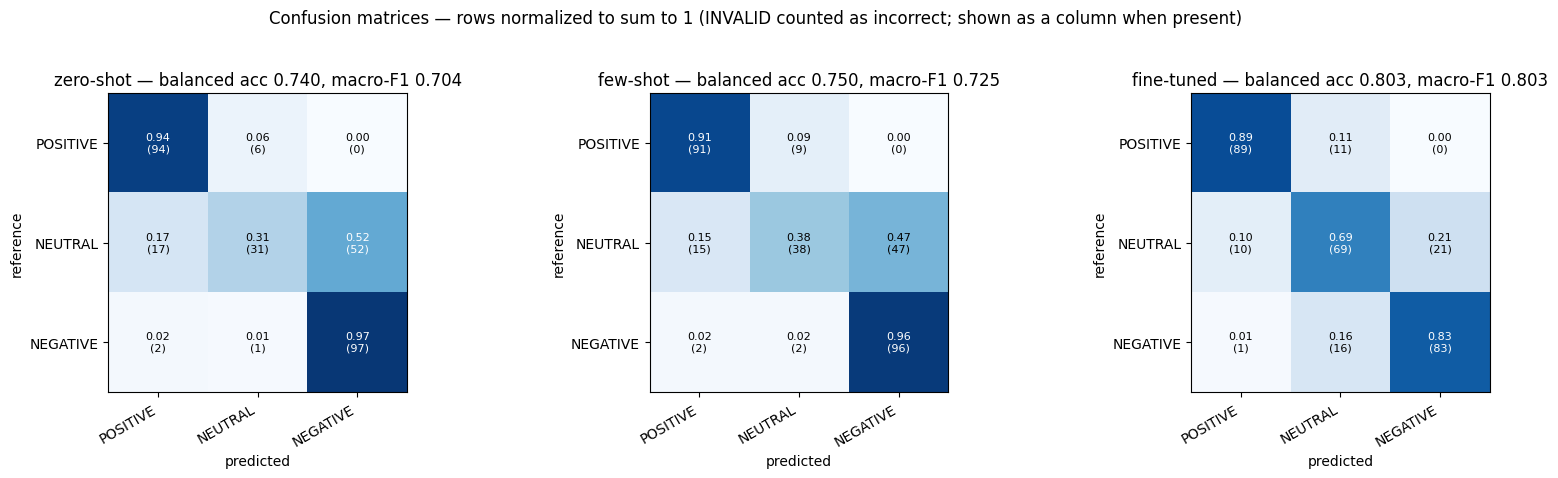

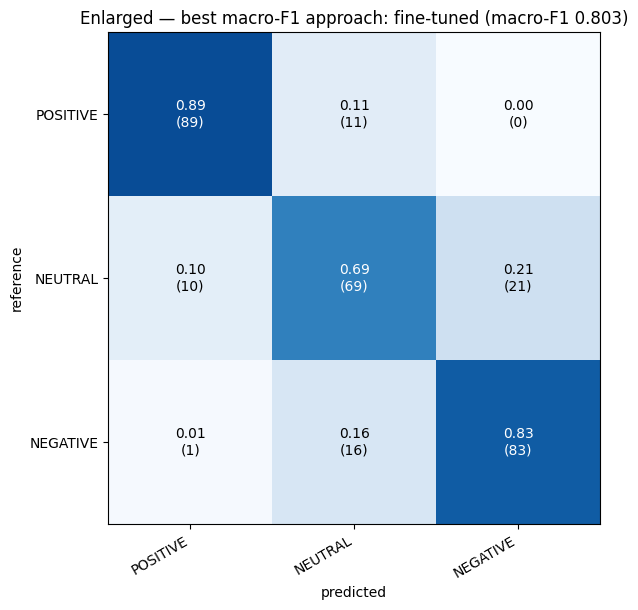

INVALID columns present: False


In [32]:
# ── Confusion matrices: 3 side-by-side (rows normalized to 1) + enlarged best ─
def norm_conf(res, classes=CLASSES):
    conf = conf_matrix(res, classes)
    cols = list(conf[classes[0]])
    totals = {t: sum(conf[t].values()) for t in classes}
    norm  = {t: [conf[t][p] / totals[t] for p in cols] for t in classes}
    return conf, norm, cols

best = max(SUM, key=lambda n: SUM[n]["macro_f1"])
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
for ax, n in zip(axes, names):
    conf, norm, cols = norm_conf(RESULTS[n])
    mat = np.array([norm[t] for t in CLASSES])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
    ax.set_yticks(range(3), CLASSES)
    ax.set_title("%s — balanced acc %.3f, macro-F1 %.3f" % (n, SUM[n]["balanced_accuracy"], SUM[n]["macro_f1"]))
    for i in range(3):
        for j in range(len(cols)):
            ax.text(j, i, "%.2f\n(%d)" % (norm[CLASSES[i]][j], conf[CLASSES[i]][cols[j]]),
                    ha="center", va="center", fontsize=8,
                    color="white" if norm[CLASSES[i]][j] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("reference")
fig.suptitle("Confusion matrices — rows normalized to sum to 1 (INVALID counted as incorrect; shown as a column when present)", y=1.03)
plt.tight_layout(); plt.show()

# Enlarged matrix for the best macro-F1 approach
conf, norm, cols = norm_conf(RESULTS[best])
fig, ax = plt.subplots(figsize=(8, 6.2))
mat = np.array([norm[t] for t in CLASSES])
ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax.set_yticks(range(3), CLASSES)
ax.set_title("Enlarged — best macro-F1 approach: %s (macro-F1 %.3f)" % (best, SUM[best]["macro_f1"]))
for i in range(3):
    for j in range(len(cols)):
        ax.text(j, i, "%.2f\n(%d)" % (norm[CLASSES[i]][j], conf[CLASSES[i]][cols[j]]),
                ha="center", va="center", fontsize=10,
                color="white" if norm[CLASSES[i]][j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("reference")
plt.tight_layout(); plt.show()
print("INVALID columns present:", any(any(not r["valid"] for r in res) for res in RESULTS.values()))


## 10. Concise non-technical report

In [33]:
# ── Section 10: concise non-technical report (numbers injected from this run) ─
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU"
best_name = max(SUM, key=lambda n: SUM[n]["macro_f1"])
worst_cm = min(SUM[best_name]["per_class"], key=lambda pc: pc["correct"])
pvals_str = "; ".join("%s vs %s: p=%.5f" % (a, b, p) for a, b, *_r, p in pair_results)
sig_any = any(p < 0.05 for a, b, *_r, p in pair_results)
sig_word = "some pairwise differences ARE statistically significant (p<0.05)" if sig_any \
    else "no pairwise difference reaches statistical significance (p<0.05)"
gain = SUM[best_name]["macro_f1"] - SUM["few-shot"]["macro_f1"]
if gain > 0.03:
    cost_sentence = ("The fine-tune's macro-F1 beats few-shot by %.3f, a meaningful "
                     "gain on a task where one wrong class costs a third of the score; "
                     "for this assignment the training time is justified." % gain)
elif gain > 0:
    cost_sentence = ("The fine-tune beats few-shot by only %.3f macro-F1 — a small "
                     "gain for the GPU time spent; few-shot looks like the better deal." % gain)
else:
    cost_sentence = ("The fine-tune does NOT beat few-shot (%.3f lower macro-F1); "
                     "the GPU time was not justified by these results." % gain)

report = f"""
## Concise report for a non-technical reader

**What we compared.** Three ways to label 300 Amazon gift-card reviews as
POSITIVE / NEUTRAL / NEGATIVE: (1) zero-shot prompting of the hosted
Qwen3.6-35B-A3B model (mathematically 35B parameters total, ~3B active per
token), (2) same model with 6 few-shot examples, and (3) a small open model,
Qwen2.5-3B (3B parameters), fine-tuned for this task with QLoRA. All three saw
the same 300 reviews (100 per class), drawn by index from the Gift Cards
category of the Amazon Reviews '23 dataset.

**Models and training.** The hosted model runs on the class endpoint
(dobolyi.com:9001) as a 4-bit AWQ quantized model and was not modified. The
fine-tuned model is Qwen2.5-3B-Instruct in dynamic 4-bit (Unsloth), trained on
900 fixed training reviews (300 per class) for 2 epochs, learning rate 2e-4,
LoRA rank 16, batch 4 with gradient accumulation 2, cosine schedule, on a
{GPU} (16 GB) — wall-clock training took ~{train_wall_s} s on that GPU.

**Why a small model?** A 3B QLoRA fine-tune fits on the free T4 in well under
an hour, needs no expensive serving, and — being task-specific — can beat a
much larger general model on a narrow task. Few-shot (6 examples) was chosen
because it is the cheapest way to give the big model the task format without
retraining; 2 examples per class keeps the prompt small and auditable.

**Which approach did best.** {best_name} had the highest macro-F1
({SUM[best_name]['macro_f1']:.3f}) and balanced accuracy
({SUM[best_name]['balanced_accuracy']:.3f}); see the enlarged matrix. Typical
errors: {worst_cm['class']} was the weakest class for the winner
({worst_cm['correct']}/{worst_cm['total']} correct), mostly confused with its
closest neighbor — the limit of a short one-word training signal for genuinely
ambiguous 3-star reviews.

**What the statistics support.** Exact pairwise McNemar: {pvals_str}. So
{sig_word}. What this cannot tell us: the three approaches are not independent
(fine-tuning starts from a sibling of the hosted family, and all share the same
test set); the test set is balanced by design while real reviews are ~90%
positive; and 300 reviews gives limited resolution for per-class claims.

**Does the gain justify the cost?** {cost_sentence}

**One decision we revisited with the agent.** Invalid model outputs: we agreed
strictly to trim/normalize and accept only the three labels, recording anything
else as INVALID and counting it as incorrect (never guessing). We checked this
actually matters by counting INVALID responses explicitly; the confusion
matrices include an INVALID column whenever one occurs, so the reader sees the
contract being enforced rather than silently repaired.
"""
print(report)



## Concise report for a non-technical reader

**What we compared.** Three ways to label 300 Amazon gift-card reviews as
POSITIVE / NEUTRAL / NEGATIVE: (1) zero-shot prompting of the hosted
Qwen3.6-35B-A3B model (mathematically 35B parameters total, ~3B active per
token), (2) same model with 6 few-shot examples, and (3) a small open model,
Qwen2.5-3B (3B parameters), fine-tuned for this task with QLoRA. All three saw
the same 300 reviews (100 per class), drawn by index from the Gift Cards
category of the Amazon Reviews '23 dataset.

**Models and training.** The hosted model runs on the class endpoint
(dobolyi.com:9001) as a 4-bit AWQ quantized model and was not modified. The
fine-tuned model is Qwen2.5-3B-Instruct in dynamic 4-bit (Unsloth), trained on
900 fixed training reviews (300 per class) for 2 epochs, learning rate 2e-4,
LoRA rank 16, batch 4 with gradient accumulation 2, cosine schedule, on a
Tesla T4 (16 GB) — wall-clock training took ~333.7 s on that GPU.

**Why a small model